In [18]:
import sys
import os

print("Python executable:", sys.executable)
print("Python version:   ", sys.version.split()[0])
print("Virtual env:      ", os.environ.get("VIRTUAL_ENV", "❌ NONE (not a venv!)"))
print("Kernel name:      ", os.environ.get("JPY_PARENT_PYTHON", "n/a"))

Python executable: c:\Users\ycode\Desktop\2nd_YouCode\briefs\Classification_images_Deep_Learning\venv\Scripts\python.exe
Python version:    3.12.10
Virtual env:       C:\Users\ycode\Desktop\2nd_YouCode\briefs\Classification_images_Deep_Learning\venv
Kernel name:       n/a


# 01 — Exploration du dataset Intel Image Classification

**Objectif :** comprendre la structure du dataset, identifier les classes,
vérifier la distribution, visualiser des exemples, et préparer la stratégie
de split (train / val / test) stratifiée.

In [19]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from collections import Counter

# Make src/ importable
sys.path.append(os.path.abspath(".."))

from src.data import (
    collect_paths_and_labels,
    stratified_split,
    IMG_SIZE,
    SEED,
)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

## 1. Chargement des chemins et labels

On parcourt le dossier `seg_train` (le seul dossier labellisé).
Chaque sous-dossier = une classe.

In [20]:
DATA_DIR = "../Intel_Image_Classification/seg_train_test/seg_train"

paths, labels, class_names = collect_paths_and_labels(DATA_DIR)

print("Total images :", len(paths))
print("Classes      :", class_names)
print("Label range  :", labels.min(), "→", labels.max())

Total images : 17034
Classes      : ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Label range  : 0 → 5


## 2. Distribution des classes

In [21]:
counts = Counter(labels)
df_counts = pd.DataFrame({
    "class": class_names,
    "count": [counts[i] for i in range(len(class_names))],
})
df_counts["pct"] = (df_counts["count"] / df_counts["count"].sum() * 100).round(2)
df_counts

,class,count,pct
0,buildings,2628,15.43
1,forest,2745,16.11
2,glacier,2957,17.36
3,mountain,3037,17.83
4,sea,2784,16.34
5,street,2883,16.92


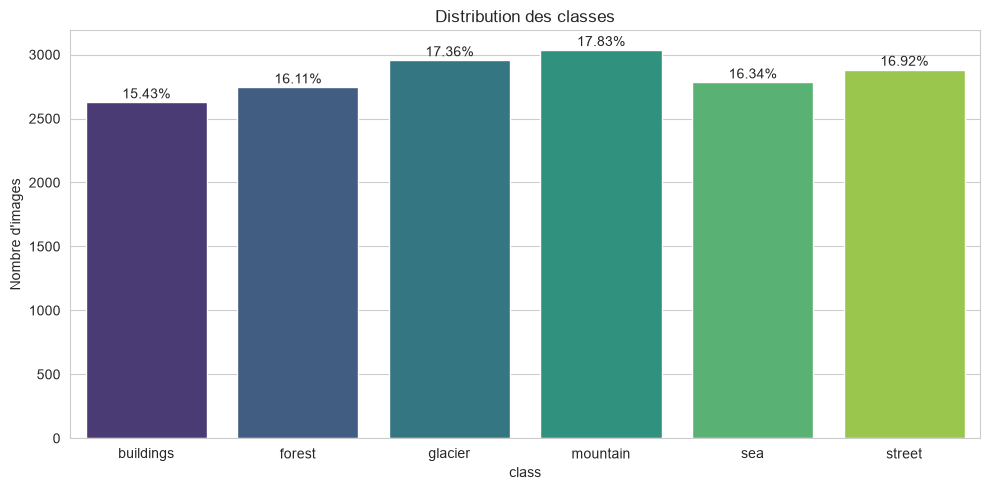

In [22]:
plt.figure(figsize=(10, 5))
sns.barplot(data=df_counts, x="class", y="count", hue="class", palette="viridis", legend=False)
plt.title("Distribution des classes")
plt.ylabel("Nombre d'images")
for i, row in df_counts.iterrows():
    plt.text(i, row["count"] + 30, f'{row["pct"]}%', ha="center")
plt.tight_layout()
plt.show()

## 3. Visualisation d'exemples par classe

On affiche 3 images aléatoires par classe pour vérifier
visuellement la cohérence entre l'image et son label.

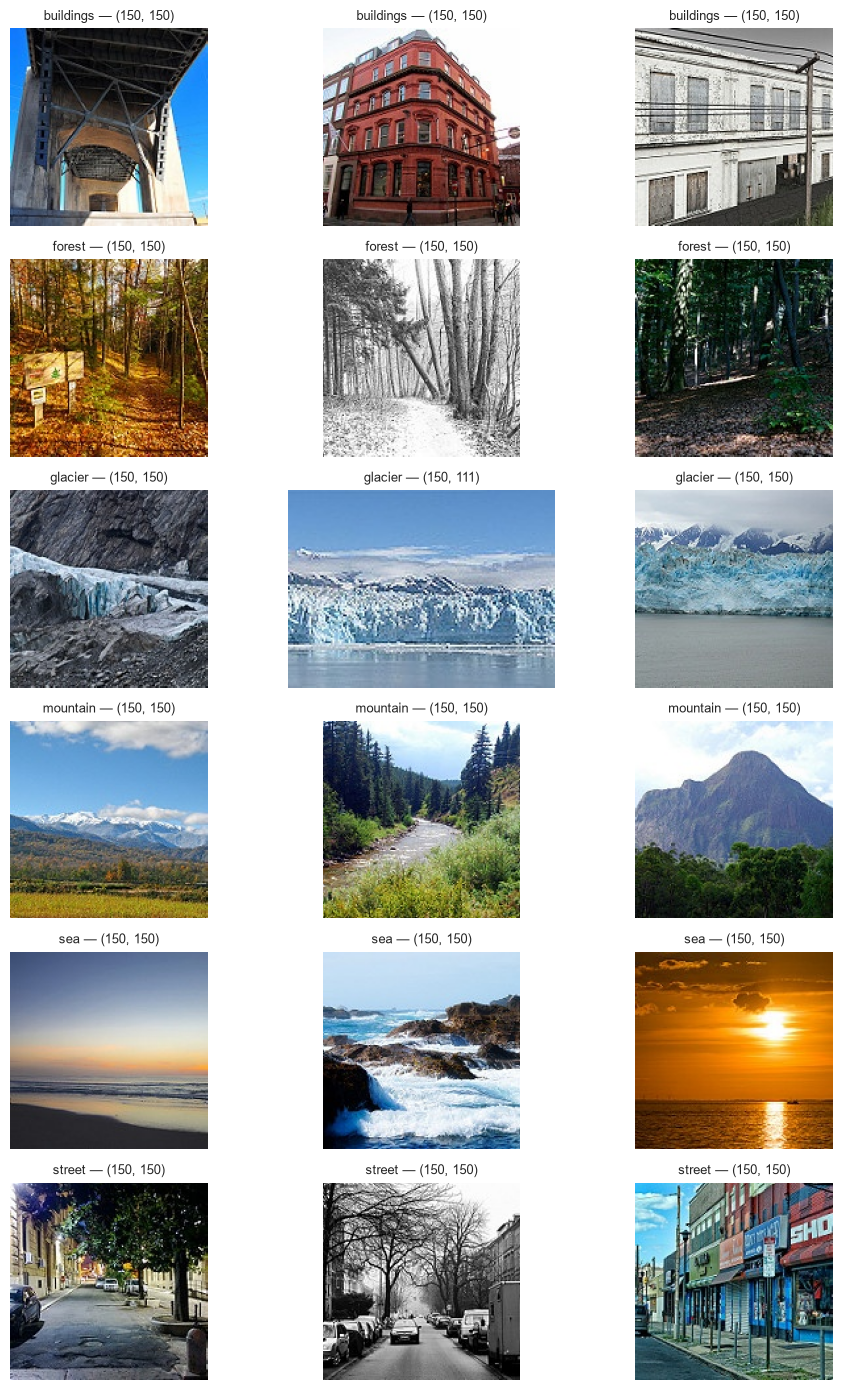

In [23]:
import random

random.seed("40")

fig, axes = plt.subplots(len(class_names), 3, figsize=(10, 14))

for row, cls_idx in enumerate(range(len(class_names))):
    cls_paths = [p for p, l in zip(paths, labels) if l == cls_idx]
    samples = random.sample(cls_paths, 3)
    for col, p in enumerate(samples):
        img = Image.open(p)
        axes[row, col].imshow(img)
        axes[row, col].axis("off")
        axes[row, col].set_title(
            f"{class_names[cls_idx]} — {img.size}", fontsize=9
        )

plt.tight_layout()
plt.show()

## 4. Vérification des dimensions et modes couleur

On échantillonne 500 images pour vérifier :
- les dimensions (width × height) ;
- le mode couleur (RGB, L = grayscale, etc.).

In [24]:
sample_size = 1000
sample_paths = random.sample(list(paths), sample_size)

sizes, modes = [], []
for p in sample_paths:
    with Image.open(p) as im:
        sizes.append(im.size)      # (width, height)
        modes.append(im.mode)

size_df = pd.DataFrame(sizes, columns=["width", "height"])
print("Dimensions (échantillon de 1000) :")
print(size_df.describe().round(1))
print("\nModes couleur :", Counter(modes))

Dimensions (échantillon de 1000) :
        width  height
count  1000.0  1000.0
mean    150.0   149.9
std       0.0     1.8
min     150.0   110.0
25%     150.0   150.0
50%     150.0   150.0
75%     150.0   150.0
max     150.0   150.0

Modes couleur : Counter({'RGB': 1000})


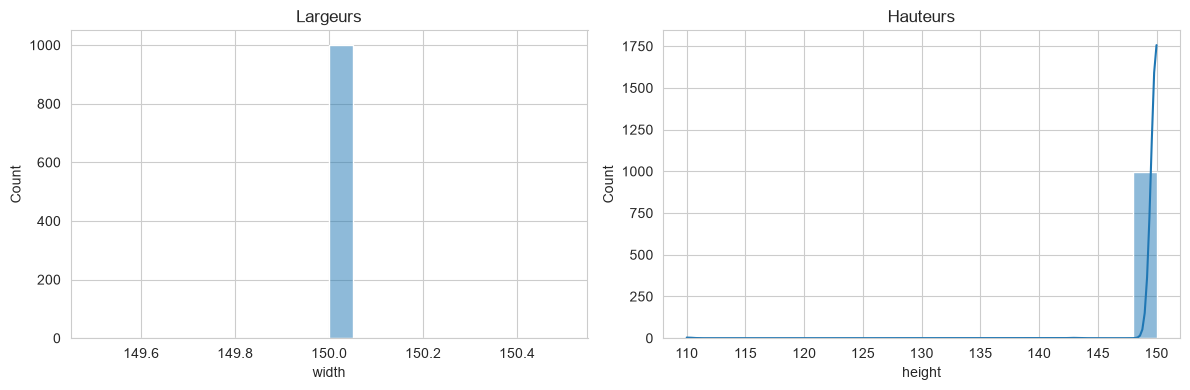

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(size_df["width"],  bins=20, ax=axes[0], kde=True).set_title("Largeurs")
sns.histplot(size_df["height"], bins=20, ax=axes[1], kde=True).set_title("Hauteurs")
plt.tight_layout()
plt.show()

## 5. Split stratifié — Train / Validation / Test

- **Train (70%)** : apprendre les poids du CNN
- **Validation (15%)** : tuner les hyperparamètres + EarlyStopping
- **Test (15%)** : évaluation finale, jamais vu à l'entraînement

⚠️ La Data Augmentation sera appliquée **uniquement au train**.

In [26]:
X_train, X_val, X_test, y_train, y_val, y_test = stratified_split(
    paths, labels, ratios=(0.7, 0.15, 0.15), seed=SEED
)

print(f"Train : {len(X_train):>6} images")
print(f"Val   : {len(X_val):>6} images")
print(f"Test  : {len(X_test):>6} images")
print(f"Total : {len(X_train) + len(X_val) + len(X_test)} images")

Train :  11923 images
Val   :   2555 images
Test  :   2556 images
Total : 17034 images


## 6. Vérification de la stratification

On compare la distribution des classes dans les 3 splits.
Les proportions doivent être quasi identiques.

In [27]:
def class_ratio(y, name):
    s = pd.Series(y).value_counts(normalize=True).sort_index()
    s.name = name
    return s

dist = pd.concat([
    class_ratio(y_train, "train"),
    class_ratio(y_val,   "val"),
    class_ratio(y_test,  "test"),
], axis=1)
dist.index = class_names
dist = (dist * 100).round(2)
dist

,train,val,test
buildings,15.42,15.46,15.41
forest,16.11,16.13,16.12
glacier,17.36,17.34,17.37
mountain,17.83,17.81,17.84
sea,16.35,16.36,16.31
street,16.93,16.91,16.94


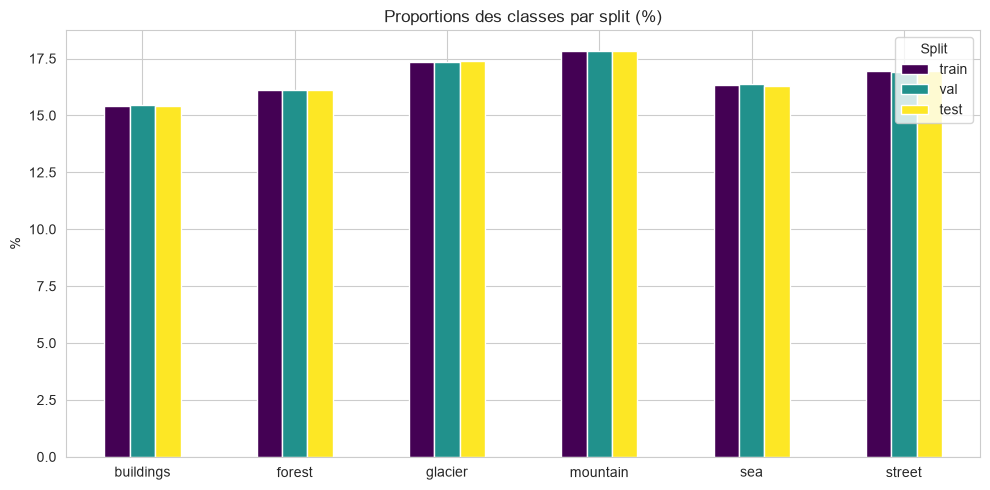

In [28]:
dist.plot(kind="bar", figsize=(10, 5), colormap="viridis")
plt.title("Proportions des classes par split (%)")
plt.ylabel("%")
plt.xticks(rotation=0)
plt.legend(title="Split")
plt.tight_layout()
plt.show()

## 7. Sauvegarde du split (reproductibilité)

On sauvegarde les chemins + labels de chaque split dans `data/splits.npz`.
Les notebooks 02, 03, 04 utiliseront **ce même split** — jamais recalculé.

In [29]:
os.makedirs("../data", exist_ok=True)

np.savez(
    "../data/splits.npz",
    X_train=X_train, y_train=y_train,
    X_val=X_val,     y_val=y_val,
    X_test=X_test,   y_test=y_test,
    class_names=np.array(class_names),
)

print("✅ Split sauvegardé → ../data/splits.npz")
print("   Fichiers enregistrés :")
print("   - X_train, y_train :", len(X_train))
print("   - X_val,   y_val   :", len(X_val))
print("   - X_test,  y_test  :", len(X_test))
print("   - class_names      :", class_names)

✅ Split sauvegardé → ../data/splits.npz
   Fichiers enregistrés :
   - X_train, y_train : 11923
   - X_val,   y_val   : 2555
   - X_test,  y_test  : 2556
   - class_names      : ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [30]:
loaded = np.load("../data/splits.npz", allow_pickle=True)

print("Keys          :", list(loaded.keys()))
print("X_train shape :", loaded["X_train"].shape)
print("y_train shape :", loaded["y_train"].shape)
print("class_names   :", loaded["class_names"])

Keys          : ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'class_names']
X_train shape : (11923,)
y_train shape : (11923,)
class_names   : ['buildings' 'forest' 'glacier' 'mountain' 'sea' 'street']


## ✅ Résumé de l'exploration

| Aspect | Résultat |
|--------|----------|
| Images labellisées | 17 034 |
| Classes | 6 (buildings, forest, glacier, mountain, sea, street) |
| Distribution | Équilibrée (~15–18 % par classe) |
| Dimensions | Toutes 150×150 (quelques hauteurs < 150 à redimensionner) |
| Modes couleur | 100 % RGB |
| Données corrompues | Aucune détectée |
| Split | 70 / 15 / 15 **stratifié** (SEED = 42) |
| Sauvegarde | `data/splits.npz` |
